# 数据分析
分析 low-light 图像和正常图像的亮度差异

1. 分析图：对比分析 LOL 数据集中低光照图像和正常光照图像的亮度差异，从直方图、增益、映射曲线三个角度分析

Get L channel done.
 - low_l:    dynamic range = [0.00, 0.47], mean = 0.11
 - normal_l: dynamic range = [0.03, 1.00], mean = 0.63
 - gain_l(raw): max = 121154.8, mean = 12.62
 - gain_l(clip): dynamic range = [2.12, 100.00], mean = 8.58
 - gain_l > 100 pixels: 0.09%


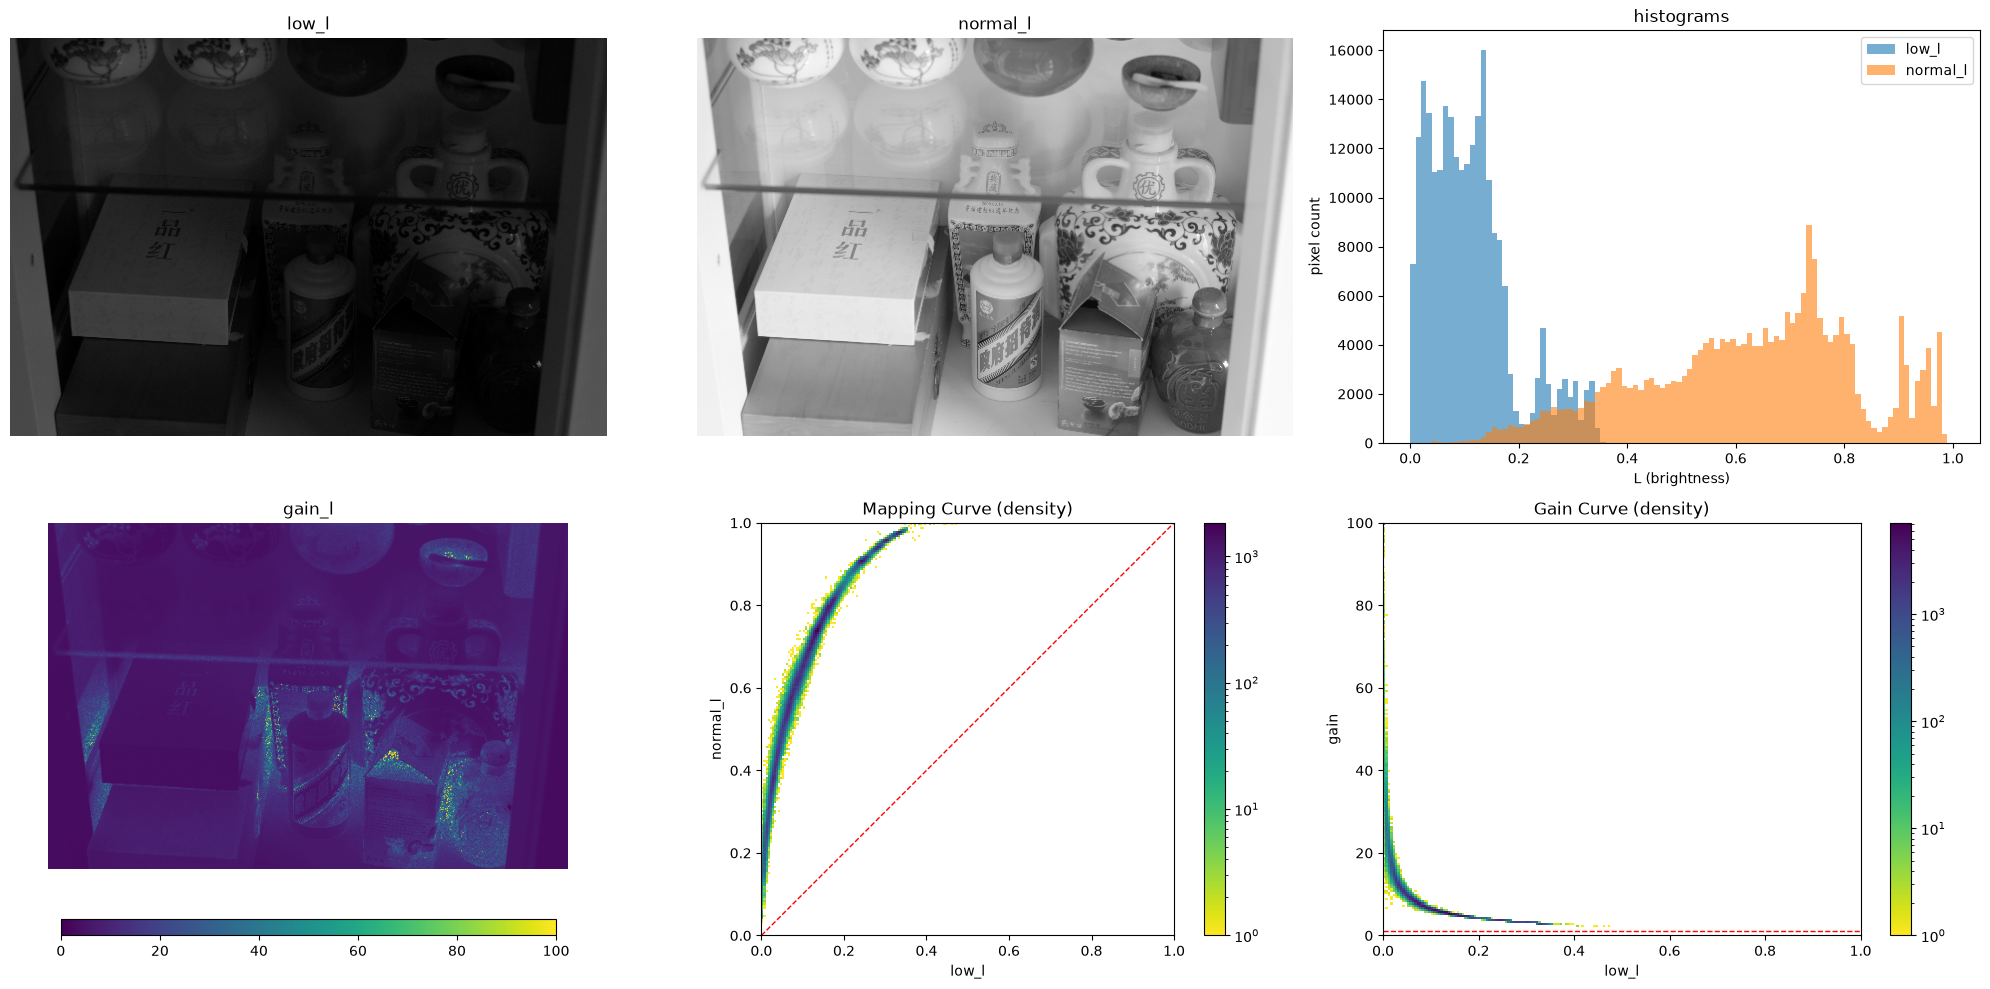

In [2]:
import numpy
import cv2
import matplotlib.colors as mcolors
from lowlight_image_enhance import utils, colorspace
from lowlight_image_enhance.analysis import ana_light
import matplotlib.pyplot as plt

# 0. 参数
LOW_MIN = 1e-6       # 仅防除零的最小分母

# 1. read an image
# 注：物理目录仍为 high/（LOL 数据集原始命名），这里 normal 指"正常光图"
low_bgr_u8 = utils.imread("low/44.png")
normal_bgr_u8 = utils.imread("high/44.png")

# 2. normalize
low_bgr_f32 = utils.normalize(low_bgr_u8)
normal_bgr_f32 = utils.normalize(normal_bgr_u8)

# 3. convert to LCH
low_lch = colorspace.BGR2LCH(low_bgr_f32)
normal_lch = colorspace.BGR2LCH(normal_bgr_f32)

# 4. get L channel
low_l = low_lch[:, :, 0]
normal_l = normal_lch[:, :, 0]

# 5. 统计信息
gain_raw = normal_l / numpy.maximum(low_l, LOW_MIN)   # 真实增益（可能很大）
gain_clip = numpy.minimum(gain_raw, ana_light.GAIN_VMAX)
exceed = gain_raw > ana_light.GAIN_VMAX
percent_exceed = 100.0 * numpy.sum(exceed) / low_l.size

print("Get L channel done.")
print(f" - low_l:    dynamic range = [{low_l.min():.2f}, {low_l.max():.2f}], mean = {low_l.mean():.2f}")
print(f" - normal_l: dynamic range = [{normal_l.min():.2f}, {normal_l.max():.2f}], mean = {normal_l.mean():.2f}")
print(f" - gain_l(raw): max = {gain_raw.max():.1f}, mean = {gain_raw.mean():.2f}")
print(f" - gain_l(clip): dynamic range = [{gain_clip.min():.2f}, {gain_clip.max():.2f}], mean = {gain_clip.mean():.2f}")
print(f" - gain_l > {ana_light.GAIN_VMAX:.0f} pixels: {percent_exceed:.2f}%")

# 6. 调用分析图函数（2x3 详细分析图）
ana_light.plot_pair(low_l, normal_l)
plt.show()

2. 对比图：用于对比多个增益算法的增益效果，分析逻辑于分析图相同

In [ ]:
# ---- 使用分析/对比图工具 ----
import numpy
from lowlight_image_enhance import utils, colorspace, algorithms
from lowlight_image_enhance.analysis import ana_light
import matplotlib.pyplot as plt

# 1. 读取并转换到 LCH，取 L 层
low_bgr_u8 = utils.imread("low/44.png")
normal_bgr_u8 = utils.imread("high/44.png")
low_l = colorspace.BGR2LCH(utils.normalize(low_bgr_u8))[:, :, 0]
normal_l = colorspace.BGR2LCH(utils.normalize(normal_bgr_u8))[:, :, 0]

# 2. 几种算法的增益结果
he_l = algorithms.histogram.equalize(low_l)
gamma_l = algorithms.curves.gamma(low_l, 0.35)
kaga_l = algorithms.curves.kaga(low_l)

# 3. 调用工具画对比图（参照 + 算法各一行）
ana_light.plot_compare(low_l, ref=normal_l, gamma=gamma_l, he=he_l, kaga=kaga_l)
plt.show()